Dataset Preview:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Shape: (150, 5)

Original Number of Features: 4

Original Data Shape: (150, 4)
Reduced Data Shape: (150, 2)

Principal Components:
[[-0.52106591  0.26934744 -0.5804131  -0.56485654]
 [ 0.37741762  0.92329566  0.02449161  0.06694199]]

Eigenvalues:
[2.93808505 0.9201649 ]

Explained Variance Ratio:
PC1: 72.96%
PC2: 22.85%

Total Variance Retained: 95.81%


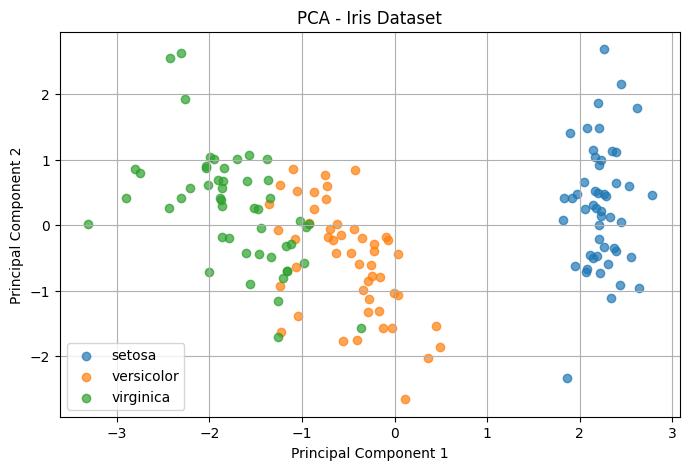


Mean Squared Reconstruction Error: 0.0419

Reduced Dataset:
        PC1       PC2 species
0  2.264703  0.480027  setosa
1  2.080961 -0.674134  setosa
2  2.364229 -0.341908  setosa
3  2.299384 -0.597395  setosa
4  2.389842  0.646835  setosa


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load Iris Dataset
# --------------------------------------------------

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset Preview:")
print(df.head())

print("\nDataset Shape:", df.shape)

# --------------------------------------------------
# 2. Select Numerical Features
# --------------------------------------------------

X = df.drop(columns=["species"], errors="ignore")
X = X.select_dtypes(include=[np.number])
X = X.fillna(X.mean())

# Save species labels for visualization only
labels = df["species"]

print("\nOriginal Number of Features:", X.shape[1])

# --------------------------------------------------
# 3. Standardize the Features
# --------------------------------------------------

X_mean = X.mean()
X_std = X.std(ddof=0).replace(0, 1)

X_scaled = ((X - X_mean) / X_std).to_numpy()

# --------------------------------------------------
# 4. PCA Implementation From Scratch
# --------------------------------------------------

class PCA:

    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.mean_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n_samples, n_features = X.shape

        if n_samples < 2:
            raise ValueError("PCA requires at least two samples.")

        k = n_features if self.n_components is None else self.n_components

        if not isinstance(k, (int, np.integer)) or not 1 <= k <= min(
            n_samples, n_features
        ):
            raise ValueError("Invalid number of components.")

        # Center the data
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Eigenvalues and eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort in descending order
        indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[indices]
        eigenvectors = eigenvectors[:, indices]

        # Remove tiny negative numerical errors
        eigenvalues = np.maximum(eigenvalues, 0)

        # Explained variance ratio
        total_variance = np.sum(eigenvalues)

        if total_variance > 0:
            ratios = eigenvalues / total_variance
        else:
            ratios = np.zeros_like(eigenvalues)

        # Select top components
        self.components_ = eigenvectors[:, :k].T
        self.explained_variance_ = eigenvalues[:k]
        self.explained_variance_ratio_ = ratios[:k]

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        X_centered = X - self.mean_
        return X_centered @ self.components_.T

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self, X_projected):
        return X_projected @ self.components_ + self.mean_


# --------------------------------------------------
# 5. Reduce Four Features to Two Components
# --------------------------------------------------

pca = PCA(n_components=2)

transformed_data = pca.fit_transform(X_scaled)

print("\nOriginal Data Shape:", X_scaled.shape)
print("Reduced Data Shape:", transformed_data.shape)

# --------------------------------------------------
# 6. Display PCA Results
# --------------------------------------------------

print("\nPrincipal Components:")
print(pca.components_)

print("\nEigenvalues:")
print(pca.explained_variance_)

print("\nExplained Variance Ratio:")

for i, ratio in enumerate(pca.explained_variance_ratio_, 1):
    print(f"PC{i}: {ratio * 100:.2f}%")

total_explained = np.sum(pca.explained_variance_ratio_) * 100

print(f"\nTotal Variance Retained: {total_explained:.2f}%")

# --------------------------------------------------
# 7. Visualize the Two Principal Components
# --------------------------------------------------

plt.figure(figsize=(8, 5))

for species in labels.unique():
    mask = labels == species

    plt.scatter(
        transformed_data[mask, 0],
        transformed_data[mask, 1],
        label=species,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 8. Reconstruct Data and Calculate Error
# --------------------------------------------------

reconstructed_data = pca.inverse_transform(transformed_data)

reconstruction_error = np.mean(
    (X_scaled - reconstructed_data) ** 2
)

print("\nMean Squared Reconstruction Error:",
      round(reconstruction_error, 4))

# --------------------------------------------------
# 9. Display Reduced Dataset
# --------------------------------------------------

reduced_df = pd.DataFrame(
    transformed_data,
    columns=["PC1", "PC2"]
)

reduced_df["species"] = labels.to_numpy()

print("\nReduced Dataset:")
print(reduced_df.head())
